# TSM-CAM: From Locations to a QAOA Route

Locations → Distance matrix → Hamiltonian → QAOA → Route. Uses straight-line kilometers and Qiskit Aer simulation; QAOA does not guarantee the optimum.

In [1]:
from pathlib import Path
import sys
import json
import numpy as np
import matplotlib.pyplot as plt
import networkx as nx

# When saved in tsm-cam, the current directory or its parent is detected.
# Change PROJECT_ROOT manually if your project is somewhere else.
search_roots = [Path.cwd(), *Path.cwd().parents,
                Path('/Users/nak/CADT/projects/tsm-cam')]
PROJECT_ROOT = next((p for p in search_roots
                     if (p / 'app/quantum/qaoa.py').is_file()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError('Set PROJECT_ROOT to your tsm-cam directory.')
sys.path.insert(0, str(PROJECT_ROOT))

from app.classical.locations import build_straight_distance_matrix
from app.quantum.qaoa import create_graph, create_hamiltonian

plt.rcParams.update({'figure.dpi': 130, 'font.size': 11})
NAVY, TEAL, PURPLE = '#08134d', '#008c95', '#8046e8'
print('Project:', PROJECT_ROOT)


Project: /Users/nak/CADT/projects/tsm-cam


## 1. Read locations and resolve coordinates

Load the departure and destinations with their coordinates. Nodes represent cities; connections are straight lines.

0: Phnom Penh: lat=11.57, lon=104.92
1: Takeo: lat=10.99, lon=104.78
2: Kampong Cham: lat=11.99, lon=105.46
3: Siem Reap: lat=13.36, lon=103.86


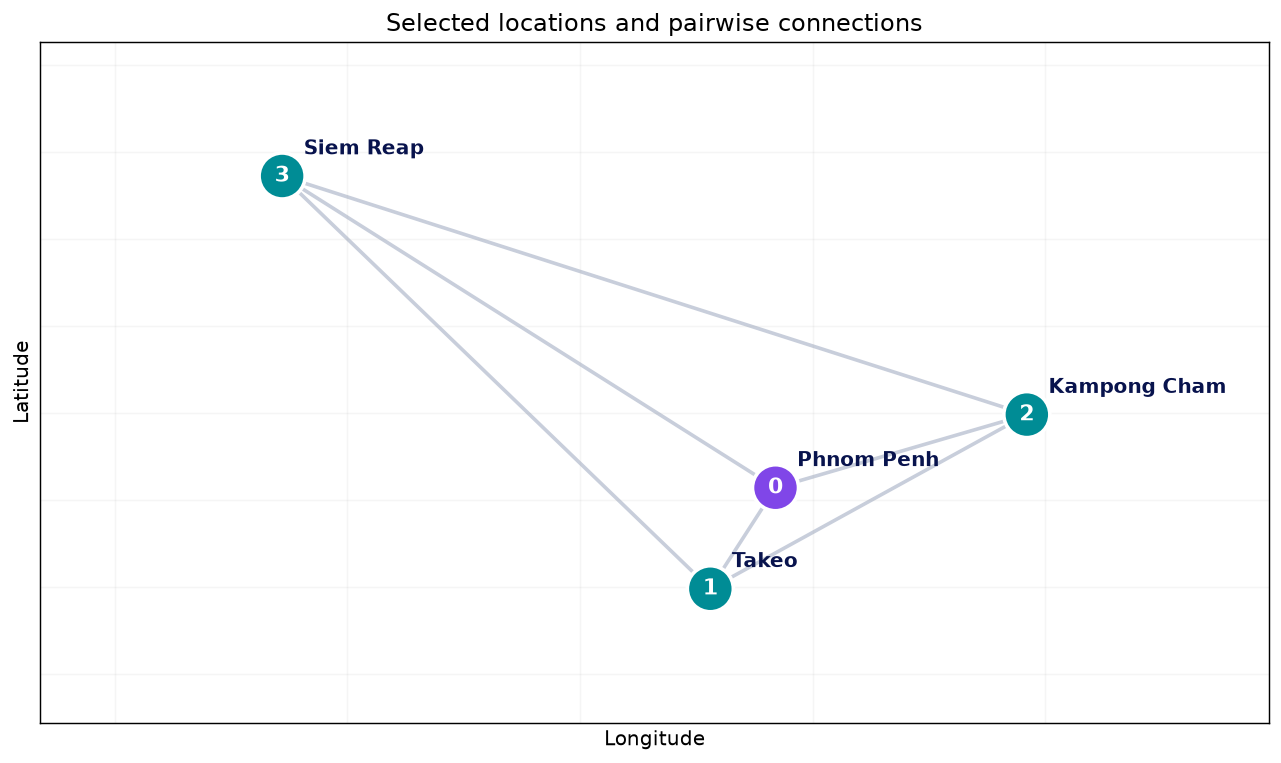

In [2]:
CITY_NAMES = ['Phnom Penh', 'Takeo', 'Kampong Cham', 'Siem Reap']
province_pins = json.loads((PROJECT_ROOT / 'static/data/provinces.json').read_text())
by_name = {p['name'].casefold(): p for p in province_pins}
assert 2 <= len(CITY_NAMES) <= 4, 'Select departure plus 1–3 destinations.'
assert len(set(n.casefold() for n in CITY_NAMES)) == len(CITY_NAMES)
locations = [dict(by_name[name.casefold()]) for name in CITY_NAMES]
n = len(locations)
for i, location in enumerate(locations):
    print(f"{i}: {location['name']}: lat={location['latitude']}, lon={location['longitude']}")

positions = {i: (p['longitude'], p['latitude']) for i, p in enumerate(locations)}
node_colors = [PURPLE if i == 0 else TEAL for i in range(n)]
fig, ax = plt.subplots(figsize=(10, 6))
graph = nx.complete_graph(n)
nx.draw_networkx_edges(graph, positions, ax=ax, edge_color='#c8cedb', width=2)
nx.draw_networkx_nodes(graph, positions, ax=ax, node_color=node_colors,
                       node_size=650, edgecolors='white', linewidths=2)
nx.draw_networkx_labels(graph, positions, labels={i: str(i) for i in range(n)},
                        ax=ax, font_color='white', font_weight='bold')
for i, (lon, lat) in positions.items():
    ax.annotate(locations[i]['name'], (lon, lat), xytext=(12, 12),
                textcoords='offset points', color=NAVY, fontweight='bold')
ax.set(xlabel='Longitude', ylabel='Latitude',
       title='Selected locations and pairwise connections')
ax.margins(0.25)
ax.grid(alpha=0.12)
plt.tight_layout()
plt.show()


## 2. Calculate distances and build the matrix

Calculate pairwise Haversine distances. Each matrix entry is a distance in kilometers.

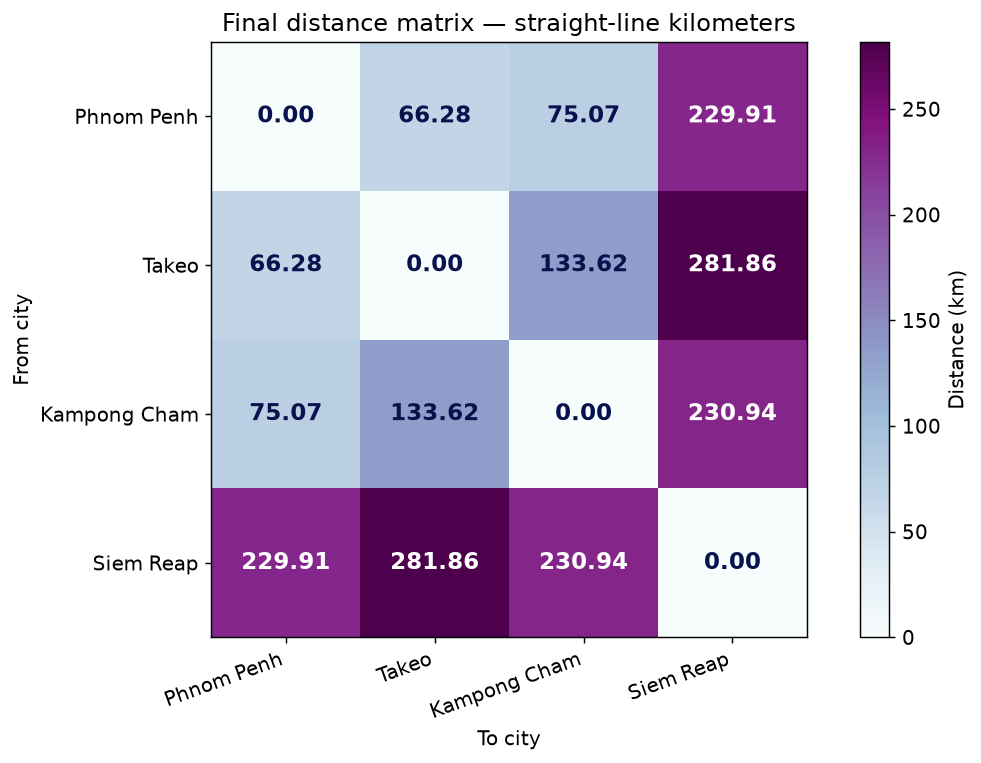

Numeric matrix passed to the TSP model:
[[  0.    66.28  75.07 229.91]
 [ 66.28   0.   133.62 281.86]
 [ 75.07 133.62   0.   230.94]
 [229.91 281.86 230.94   0.  ]]


In [3]:
matrix_data = build_straight_distance_matrix(locations)
distance_matrix = np.asarray(matrix_data['distances'], dtype=float)
assert distance_matrix.shape == (n, n)
assert np.allclose(distance_matrix, distance_matrix.T)
assert np.allclose(np.diag(distance_matrix), 0)

fig, ax = plt.subplots(figsize=(9, 6))
heatmap = ax.imshow(distance_matrix, cmap='BuPu', vmin=0)
ax.set_xticks(range(n), CITY_NAMES, rotation=20, ha='right')
ax.set_yticks(range(n), CITY_NAMES)
ax.set(xlabel='To city', ylabel='From city',
       title='Final distance matrix — straight-line kilometers')
for i in range(n):
    for j in range(n):
        color = 'white' if distance_matrix[i, j] > distance_matrix.max() * 0.6 else NAVY
        ax.text(j, i, f'{distance_matrix[i, j]:.2f}', ha='center', va='center',
                color=color, fontsize=13, fontweight='bold')
fig.colorbar(heatmap, ax=ax, label='Distance (km)')
plt.tight_layout()
plt.show()
print('Numeric matrix passed to the TSP model:')
print(np.array2string(distance_matrix, precision=2, suppress_small=True))


In [4]:
def route_names(tour):
    return ' → '.join(CITY_NAMES[i] for i in tour)

def tour_distance(tour):
    return float(sum(distance_matrix[a, b] for a, b in zip(tour, tour[1:])))



## 3. Encode the problem for QAOA

Classically convert graph → TSP → QUBO → Hamiltonian, encoding distances and visiting rules. Four cities use 16 qubits.

In [5]:
weighted_graph = create_graph(distance_matrix)
hamiltonian, offset = create_hamiltonian(weighted_graph)
print('Cities:', n)
print('Qubits:', hamiltonian.num_qubits)
print('Ising Pauli terms:', len(hamiltonian.paulis))
print('Constant energy offset:', float(offset))
print('First five Hamiltonian terms:')
for pauli, coefficient in list(zip(hamiltonian.paulis, hamiltonian.coeffs))[:5]:
    print(f'{float(coefficient.real):.4f} * {pauli.to_label()}')


Cities: 4
Qubits: 16
Ising Pauli terms: 112
Constant energy offset: 132315.80996672346
First five Hamiltonian terms:
-16470.6859 * IIIIIIIIIIIIIIIZ
-16470.6859 * IIIIIIIIIIIIIIZI
-16470.6859 * IIIIIIIIIIIIIZII
-16470.6859 * IIIIIIIIIIIIZIII
-16525.9339 * IIIIIIIIIIIZIIII


## 4. Quantum processing: QAOA and measurement

Reuse the Step 3 Hamiltonian in QAOA, simulated by Aer with classical COBYLA optimization.

### 4.1 Configure QAOA

Fix shots at 1,024. Set initial angles, one QAOA layer and COBYLA.

In [6]:
from qiskit import transpile
from qiskit.transpiler import generate_preset_pass_manager
from qiskit_aer import AerSimulator
from qiskit_aer.primitives import SamplerV2
from qiskit_algorithms.optimizers import COBYLA
from qiskit_optimization.minimum_eigensolvers import QAOA

INITIAL_GAMMA = 0.2
INITIAL_BETA = 0.2
SHOTS = 1024
backend = AerSimulator(max_parallel_threads=4)
pass_manager = generate_preset_pass_manager(backend=backend, optimization_level=1)
sampler = SamplerV2(default_shots=SHOTS, seed=42,
    options={'backend_options': {'max_parallel_threads': 4}})
print('Shots per evaluation and final sampling:', SHOTS)
print('QAOA layers: 1 | COBYLA maxiter: 30')

Shots per evaluation and final sampling: 1024
QAOA layers: 1 | COBYLA maxiter: 30


### 4.2 Optimize beta and gamma

COBYLA adjusts the angles, not the shot count. The graph shows sampled energy.

Optimized [beta, gamma]: [-0.36428021 -0.62427017]


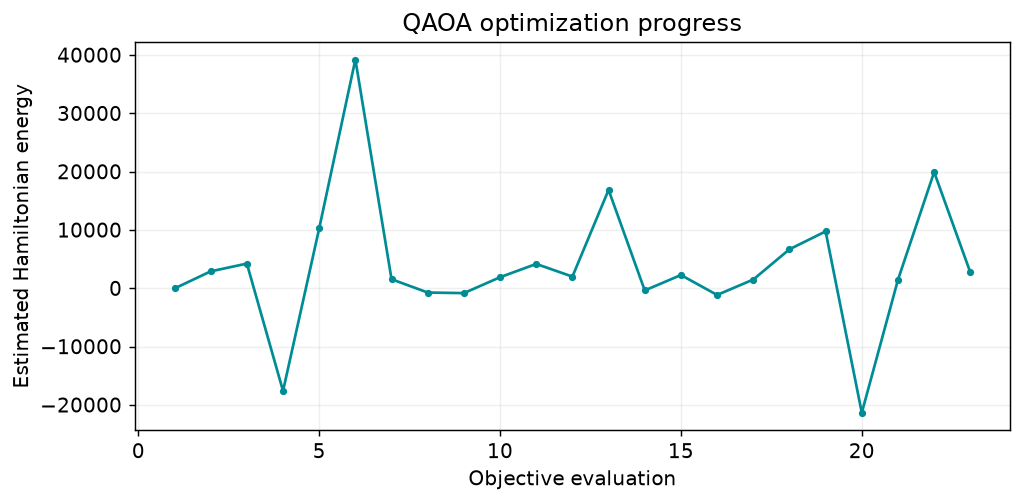

In [7]:
optimization_log = []
def record_evaluation(evaluation, parameters, mean, metadata):
    energy = float(np.real(mean))
    optimization_log.append((int(evaluation), energy))

qaoa = QAOA(
    sampler=sampler,
    optimizer=COBYLA(maxiter=30, tol=1e-3),
    reps=1,
    pass_manager=pass_manager,
    initial_point=np.array([INITIAL_BETA, INITIAL_GAMMA]),
    callback=record_evaluation,
)
qaoa_result = qaoa.compute_minimum_eigenvalue(hamiltonian)
print('Optimized [beta, gamma]:', qaoa_result.optimal_point)

evaluations, energies = zip(*optimization_log)
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(evaluations, energies, 'o-', color=TEAL, markersize=3)
ax.set(xlabel='Objective evaluation', ylabel='Estimated Hamiltonian energy',
       title='QAOA optimization progress')
ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()

### 4.3 Measure the optimized result

Sample 1,024 bitstrings. The chart shows actual counts; some assignments may be invalid.

Final sampling shots: 1024
Unique measured bitstrings: 986


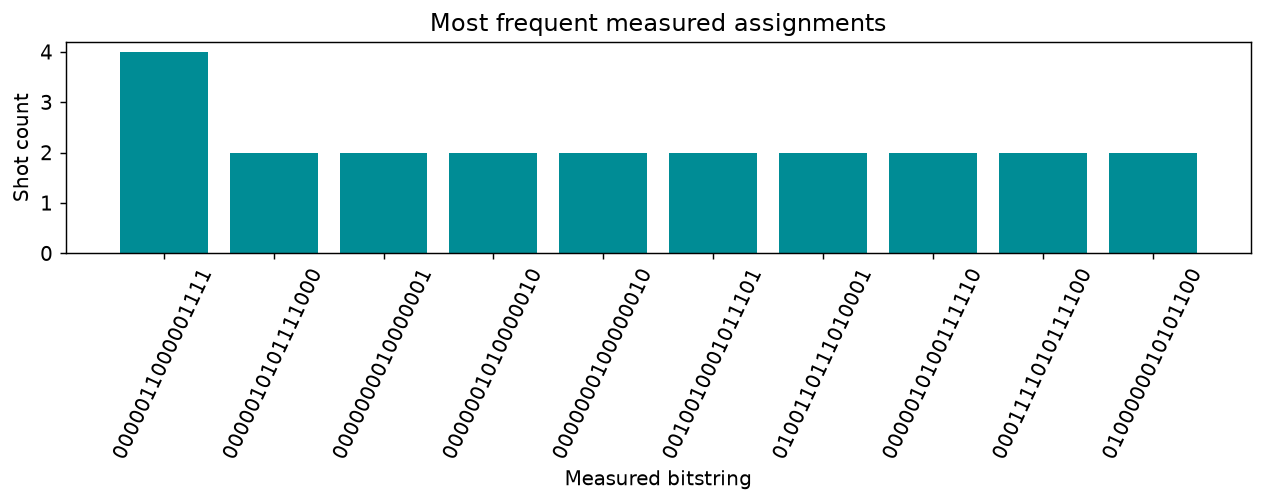

In [8]:
circuit = qaoa.ansatz.remove_final_measurements(inplace=False)
circuit = circuit.assign_parameters(qaoa_result.optimal_point)
circuit.measure_all()
compiled = transpile(circuit, backend, seed_transpiler=42)
counts = backend.run(compiled, shots=SHOTS, seed_simulator=42).result().get_counts()
assert sum(counts.values()) == SHOTS
print('Final sampling shots:', sum(counts.values()))
print('Unique measured bitstrings:', len(counts))

top_counts = sorted(counts.items(), key=lambda item: item[1], reverse=True)[:10]
fig, ax = plt.subplots(figsize=(10, 4))
ax.bar([bits for bits, count in top_counts], [count for bits, count in top_counts], color=TEAL)
ax.set(xlabel='Measured bitstring', ylabel='Shot count', title='Most frequent measured assignments')
ax.tick_params(axis='x', rotation=65)
plt.tight_layout()
plt.show()

### 4.4 Decode and validate candidates (classical)

Keep valid tours and remove duplicates. Check the optimizer’s best measurement separately without changing final counts.

In [9]:
def decode_tour(bitstring):
    assignment = np.array([int(bit) for bit in bitstring[::-1]]).reshape(n, n)
    if not (np.all(assignment.sum(axis=0) == 1) and np.all(assignment.sum(axis=1) == 1)):
        return None
    cycle = [int(np.argmax(assignment[:, p])) for p in range(n)]
    start = cycle.index(0)
    cycle = cycle[start:] + cycle[:start]
    return cycle + [0]

candidates = []
seen = set()
valid_shots = 0
for bitstring, count in counts.items():
    tour = decode_tour(bitstring)
    if tour is None:
        continue
    valid_shots += count
    if tuple(tour) not in seen:
        seen.add(tuple(tour))
        candidates.append({'tour': tour, 'bitstring': bitstring, 'source': 'Final sampling'})

best_measurement = getattr(qaoa_result, 'best_measurement', None) or {}
best_bitstring = best_measurement.get('bitstring')
best_tour = decode_tour(best_bitstring) if best_bitstring else None
if best_tour is not None and tuple(best_tour) not in seen:
    candidates.append({'tour': best_tour, 'bitstring': best_bitstring, 'source': 'Optimizer measurement'})

print(f'Valid final shots: {valid_shots}/{SHOTS} ({100*valid_shots/SHOTS:.2f}%)')
print('Valid unique route candidates:', len(candidates))
for candidate in sorted(candidates, key=lambda item: tour_distance(item['tour'])):
    print(f"{tour_distance(candidate['tour']):.2f} km | {route_names(candidate['tour'])} | {candidate['source']}")
if not candidates:
    raise RuntimeError('No valid measured tour. Adjust initial angles or optimizer budget, then rerun Step 4.')

Valid final shots: 0/1024 (0.00%)
Valid unique route candidates: 1
654.16 km | Phnom Penh → Takeo → Siem Reap → Kampong Cham → Phnom Penh | Optimizer measurement


## 5. Select and visualize the route

Choose the shortest valid measured candidate and include the return home. The grid shows city-position assignments, rotated to departure first.

SELECTED QAOA ROUTE
Candidate source: Optimizer measurement
Phnom Penh → Takeo → Siem Reap → Kampong Cham → Phnom Penh
Total straight-line distance: 654.16 km
Selected measured bitstring: 1000000101000010


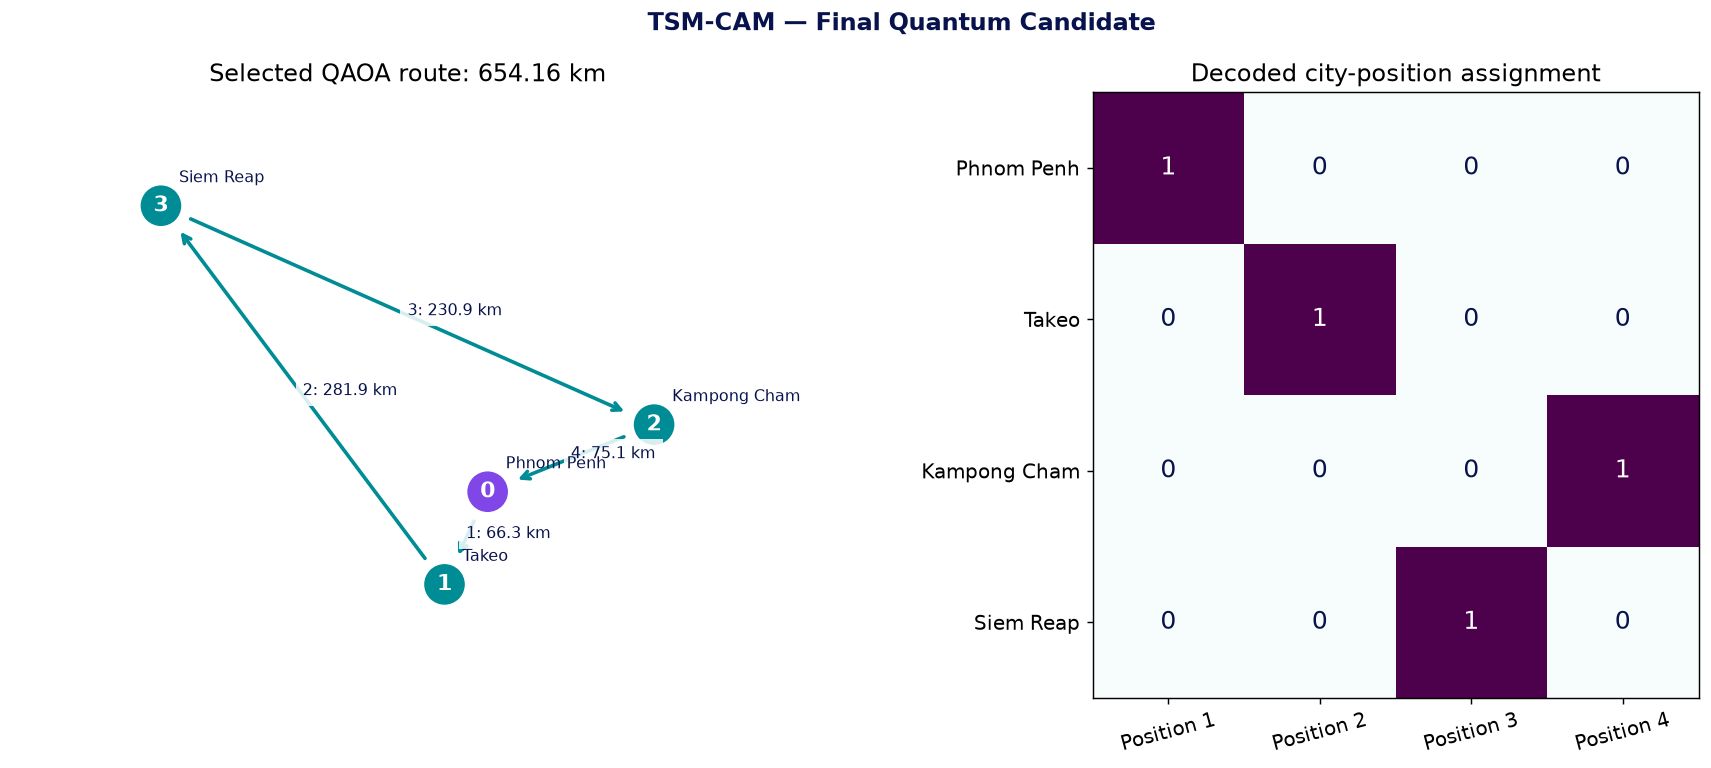

In [10]:
selected = min(candidates, key=lambda candidate: tour_distance(candidate['tour']))
selected_tour = selected['tour']
selected_distance = tour_distance(selected_tour)
print('SELECTED QAOA ROUTE')
print('Candidate source:', selected['source'])
print(route_names(selected_tour))
print(f'Total straight-line distance: {selected_distance:.2f} km')
print('Selected measured bitstring:', selected['bitstring'])

assignment = np.array([int(bit) for bit in reversed(selected['bitstring'])]).reshape(n, n)
depot_position = int(np.flatnonzero(assignment[0])[0])
assignment = np.roll(assignment, -depot_position, axis=1)
assert [int(np.flatnonzero(assignment[:, p])[0]) for p in range(n)] == selected_tour[:-1]
assert np.all(assignment.sum(axis=0) == 1)
assert np.all(assignment.sum(axis=1) == 1)

fig, (ax_route, ax_assignment) = plt.subplots(1, 2, figsize=(14, 6))
nx.draw_networkx_nodes(weighted_graph, positions, ax=ax_route, node_color=node_colors,
                       node_size=600, edgecolors='white', linewidths=2)
nx.draw_networkx_labels(weighted_graph, positions, labels={i: str(i) for i in range(n)},
                        ax=ax_route, font_color='white', font_weight='bold')
for step, (a, b) in enumerate(zip(selected_tour, selected_tour[1:]), 1):
    ax_route.annotate('', xy=positions[b], xytext=positions[a],
                      arrowprops=dict(arrowstyle='->', color=TEAL, lw=2,
                                      shrinkA=18, shrinkB=18))
    x = (positions[a][0] + positions[b][0]) / 2
    y = (positions[a][1] + positions[b][1]) / 2
    ax_route.text(x, y, f'{step}: {distance_matrix[a,b]:.1f} km', fontsize=9,
                  color=NAVY, bbox=dict(facecolor='white', edgecolor='none', alpha=0.85))
for i, (lon, lat) in positions.items():
    ax_route.annotate(CITY_NAMES[i], (lon, lat), xytext=(10, 13),
                      textcoords='offset points', fontsize=9, color=NAVY)
ax_route.margins(0.3)
ax_route.set_title(f'Selected QAOA route: {selected_distance:.2f} km')
ax_route.set_axis_off()
ax_assignment.imshow(assignment, cmap='BuPu', vmin=0, vmax=1)
ax_assignment.set_xticks(range(n), [f'Position {p+1}' for p in range(n)], rotation=15)
ax_assignment.set_yticks(range(n), CITY_NAMES)
ax_assignment.set_title('Decoded city-position assignment')
for i in range(n):
    for j in range(n):
        ax_assignment.text(j, i, str(assignment[i,j]), ha='center', va='center',
                           color='white' if assignment[i,j] else NAVY, fontsize=14)
fig.suptitle('TSM-CAM — Final Quantum Candidate', color=NAVY, fontweight='bold')
plt.tight_layout()
plt.show()


## Optional classical benchmark

Compare the selected route with exhaustive search; this does not supply the QAOA result.

In [11]:
from itertools import permutations

# Benchmark only: enumerate after the quantum route has already been selected.
benchmark_tours = [[0, *order, 0] for order in permutations(range(1, n))]
classical_best = min(benchmark_tours, key=tour_distance)
classical_distance = tour_distance(classical_best)
gap = (selected_distance - classical_distance) / classical_distance * 100 if classical_distance else 0
print('QAOA candidate:', route_names(selected_tour))
print(f'QAOA distance: {selected_distance:.2f} km')
print('Exact classical route:', route_names(classical_best))
print(f'Exact classical distance: {classical_distance:.2f} km')
print(f'Distance gap: {gap:.2f}%')
print('Matches exact minimum:', bool(np.isclose(selected_distance, classical_distance)))


QAOA candidate: Phnom Penh → Takeo → Siem Reap → Kampong Cham → Phnom Penh
QAOA distance: 654.16 km
Exact classical route: Phnom Penh → Kampong Cham → Siem Reap → Takeo → Phnom Penh
Exact classical distance: 654.16 km
Distance gap: 0.00%
Matches exact minimum: True
